<a href="https://colab.research.google.com/github/MihaiDogariu/CV3/blob/main/laborator/CV_3_Lab_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Elemente fundamentale ale unei rețele neuronale în PyTorch

Scopul acestui laborator este de a îmbina toate noțiunile discutate într-o singură aplicație. În același timp, vor fi explicate și studiate modurile de implementare ale unor aspecte cheie din dezvoltarea rețelelor neuronale folosind framework-ul PyTorch. Aplicația din acest laborator este o predicție simplă de vreme pentru ziua următoare: pornind de la observațiile meteorologice din ziua curentă, rețeaua trebuie să decidă dacă **mâine va ploua sau nu** (clasificare binară). Momentan, datele de intrare sunt sub formă vectorială (nu imagini), urmând ca acestea să fie abordate începând cu laboratorul următor.

La finalul laboratorului ar trebui să știți:
1. cum se încarcă datele cu `torch.utils.data.Dataset` și `DataLoader`;
2. cum se definește un model ca o clasă care moștenește `torch.nn.Module`;
3. cum funcționează bucla de antrenare: apelul `forward`, calculul funcției de cost, `zero_grad()`, `backward()`, `step()` și rolul lui `torch.no_grad()`;
4. cum se folosesc corect subseturile **train / val / test**;
5. ce efect au metodele de **regularizare** (L2, L1, dropout, early stopping);
6. cum arată ponderile unei rețele antrenate și ce putem învăța din ele.

## 0. Pregătirea mediului

In [1]:
import os
import random

import numpy as np
import pandas as pd # utilitar folosit pentru gestionarea bazelor de date
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split # va fi utilizat pentru împărțirea bazei de date în subseturile dorite
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

RANDOM_SEED = 1 # pentru reproductibilitate

def set_seed(seed=RANDOM_SEED):
  # fixăm toate sursele de aleatorism, astfel încât fiecare rulare să dea aceleași rezultate
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)

set_seed()

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Rulăm pe:", device)

Rulăm pe: cpu


## 1. Alegerea datelor

Folosim baza de date ["Rain in Australia"](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package?resource=download):

In [2]:
if not os.path.exists('weatherAUS.csv'):
  !gdown 1D-Ua952YzK95yPCJxzr8SWu7ZJGVROJd

Fiecare intrare din baza de date conține 23 de câmpuri de informații. Utilitarul `pandas` este specializat în gestionarea bazelor de date și are funcții speciale pentru citirea formatelor de date comune.

In [3]:
df = pd.read_csv('weatherAUS.csv') # citirea fisierului .csv <-> setul de date
df.head(15) # afisam primele 15 intrari din fisier

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No
5,2008-12-06,Albury,14.6,29.7,0.2,NaN,NaN,WNW,56.0,W,...,55.0,23.0,1009.2,1005.4,NaN,NaN,20.6,28.9,No,No
6,2008-12-07,Albury,14.3,25.0,0.0,NaN,NaN,W,50.0,SW,...,49.0,19.0,1009.6,1008.2,1.0,NaN,18.1,24.6,No,No
7,2008-12-08,Albury,7.7,26.7,0.0,NaN,NaN,W,35.0,SSE,...,48.0,19.0,1013.4,1010.1,NaN,NaN,16.3,25.5,No,No
8,2008-12-09,Albury,9.7,31.9,0.0,NaN,NaN,NNW,80.0,SE,...,42.0,9.0,1008.9,1003.6,NaN,NaN,18.3,30.2,No,Yes
9,2008-12-10,Albury,13.1,30.1,1.4,NaN,NaN,W,28.0,S,...,58.0,27.0,1007.0,1005.7,NaN,NaN,20.1,28.2,Yes,No


In [4]:
# Numărul total de intrări în baza de date și dimensiunea unei intrări:
print(df.shape)

(145460, 23)


## 2. Pre-procesarea datelor

In [5]:
# Baza de date conține o gamă largă de atribute/descriptori, însă nu ne interesează toate/toti.
# Facem o listă cu descriptorii care sunt de interes dintre toți cei disponibili
# TODO: testați cu diferiți descriptori pentru a vedea care dintre ei are o influență mai mare asupra capacității de predicție - adăugați cel puțin 2 alți descriptori existenți în baza de date
keep = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity3pm', 'Pressure9am', 'RainToday', 'RainTomorrow']
FEATURES = keep[:-1] # descriptorii de intrare
TARGET = keep[-1]    # eticheta pe care vrem să o prezicem

# Din întreaga bază de date păstrăm doar datele asociate descriptorilor selectați mai sus
# .copy() creează o bază de date nouă, independentă de df, pe care o putem modifica fără avertismente
df_keep = df[keep].copy()

# Unii dintre descriptori sunt reprezentați de valori logice binare (yes/no). Acestea trebuie interpretate sub forma unor valori pe care o rețea neuronală le poate procesa, adică valori numerice.
df_keep['RainToday'] = df_keep['RainToday'].map({'No': 0, 'Yes': 1})
df_keep['RainTomorrow'] = df_keep['RainTomorrow'].map({'No': 0, 'Yes': 1})

# De asemenea, baza de date conține intrări pentru care nu sunt disponibili toți descriptorii (valori de NaN). O soluție trivială este să eliminăm complet aceste intrări.
# TODO: propuneți o altă strategie de abordare a datelor incomplete în acest context.
df_keep = df_keep.dropna(how='any')
df_keep[['RainToday', 'RainTomorrow']] = df_keep[['RainToday', 'RainTomorrow']].astype(int)
df_keep.head(15)

,MinTemp,MaxTemp,Rainfall,Humidity3pm,Pressure9am,RainToday,RainTomorrow
0,13.4,22.9,0.6,22.0,1007.7,0,0
1,7.4,25.1,0.0,25.0,1010.6,0,0
2,12.9,25.7,0.0,30.0,1007.6,0,0
3,9.2,28.0,0.0,16.0,1017.6,0,0
4,17.5,32.3,1.0,33.0,1010.8,0,0
5,14.6,29.7,0.2,23.0,1009.2,0,0
6,14.3,25.0,0.0,19.0,1009.6,0,0
7,7.7,26.7,0.0,19.0,1013.4,0,0
8,9.7,31.9,0.0,9.0,1008.9,0,1
9,13.1,30.1,1.4,27.0,1007.0,1,0


In [6]:
# Afișăm numărul de zile în care [nu] a plouat, în valori absolute:
print("Numarul de zile in care nu a plouat: ", df_keep[TARGET].value_counts()[0])
print("Numarul de zile in care a plouat: ", df_keep[TARGET].value_counts()[1])

# Afișăm numărul de zile în care [nu] a plouat, în valori relative:
df_keep[TARGET].value_counts() / df_keep.shape[0]

Numarul de zile in care nu a plouat:  96989
Numarul de zile in care a plouat:  27550


RainTomorrow
0    0.778784
1    0.221216
Name: count, dtype: float64

Se observă că baza de date este dezechilibrată - numărul de zile în care nu a plouat este de ~3.5x mai mare decât numărul de zile în care a plouat.

In [7]:
# Putem alege o tehnică de echilibrare a bazei de date prin sub-eșantionarea clasei puternic reprezentată
# TODO: rulați algoritmul cu diferite grade de dezechilibru între cele 2 clase:
# no_rain = 3.5x rain (original)
# no_rain = 3x rain
# no_rain = 2x rain
under_sample = True

# Rezultatul este salvat în df_data, astfel încât df_keep să rămână neschimbat și celula să poată fi rulată de mai multe ori
df_data = df_keep

if under_sample:
  rain = df_keep[df_keep[TARGET]==1] # selectăm doar intrările pentru care a fost înregistrată ploaie
  no_rain = df_keep[df_keep[TARGET]==0] # selectăm doar intrările pentru care nu a fost înregistrată ploaie
  no_rain = no_rain.sample(n=len(rain), random_state=RANDOM_SEED) # alegem <len(rain)> eșantioane aleatoare din baza de date no_rain
  df_data = pd.concat([rain,no_rain],axis=0) # concatenăm cele 2 subseturi de date, formând o bază de date cu gradul dorit de dezechilibru

# TODO: propuneți o metodă de over_sample, în care clasa slab reprezentată să fie augmentată până la dimensiunea clasei puternic reprezentată

print("Numarul de zile in care a plouat: ", df_data[TARGET].value_counts()[1])
print("Numarul de zile in care nu a plouat: ", df_data[TARGET].value_counts()[0])

Numarul de zile in care a plouat:  27550
Numarul de zile in care nu a plouat:  27550


Împărțim baza de date nou formată în intrări (`x`) și ieșiri (`y`). Ieșirile reprezintă etichetele datelor de intrare. În acest context, etichetele sunt decizia plouă/nu plouă mâine.

In [8]:
x = df_data[FEATURES]
y = df_data[TARGET]

## 3. Împărțirea în train / val / test

Fiecare subset are un rol precis și **nu trebuie amestecate**:

| Subset | Proporție | La ce îl folosim |
|---|---|---|
| `train` | 70% | ajustarea ponderilor rețelei (gradienții se calculează doar pe el) |
| `val` | 15% | alegerea **hiper-parametrilor**: arhitectura, rata de învățare, regularizarea, numărul de epoci |
| `test` | 15% | **o singură** estimare finală a performanței, după ce toate deciziile au fost luate |

Protocolul pe care îl urmăm în acest laborator:
1. **Etapa de dezvoltare:** antrenăm diferite variante de modele pe `train` și le comparăm pe `val`. Alegem varianta cea mai bună.
2. **Antrenarea finală:** cu hiper-parametrii aleși, antrenăm un model nou, de la zero, pe `train + val` (mai multe date ⇒ model mai bun).
3. **Testarea:** evaluăm modelul final **o singură dată** pe `test`.

Hiper-parametrii nu trebuie optimizați direct pe `test` pentru că atunci `test` ar deveni parte din procesul de optimizare, iar performanța măsurată pe el ar fi prea optimistă: are loc "scurgere de informație" din baza de test către procesul de antrenare - am fi ales exact varianta care "se nimerește" cel mai bine pe acele date. Setul de test trebuie să rămână echivalentul unor date pe care modelul nu le-a văzut niciodată.

Funcția `train_test_split` realizează împărțirea unui set de date în doar 2 subseturi. Prin urmare, trebuie aplicată de două ori:
1. se împarte baza de date originală în `train_val` și `test`;
2. se împarte `train_val` în `train` și `val`.

Parametrul `stratify` păstrează aceeași proporție a claselor în fiecare subset.

In [9]:
train_ratio = 0.7
val_ratio = 0.15
test_ratio = 0.15

# Împărțirea bazei originale în 'train_val' și 'test':
x_train_val, x_test, y_train_val, y_test = train_test_split(x, y, test_size=test_ratio, stratify=y, random_state=RANDOM_SEED)
print('Dimensiuni baza train_val: {}\tDimensiuni baza test: {}'.format(x_train_val.shape, x_test.shape))

# Împărțirea 'train_val' în 'train' și 'val'
x_train, x_val, y_train, y_val = train_test_split(x_train_val, y_train_val, test_size=val_ratio/(val_ratio + train_ratio), stratify=y_train_val, random_state=RANDOM_SEED)
print('Dimensiuni baza train: {}\tDimensiuni baza val: {}\tDimensiuni baza test:{}'.format(x_train.shape, x_val.shape, x_test.shape))

Dimensiuni baza train_val: (46835, 6)	Dimensiuni baza test: (8265, 6)
Dimensiuni baza train: (38570, 6)	Dimensiuni baza val: (8265, 6)	Dimensiuni baza test:(8265, 6)


### Normalizarea datelor

Descriptorii au scale foarte diferite: presiunea are valori în jur de 1000, în timp ce `RainToday` este 0 sau 1. O rețea neuronală se antrenează mult mai ușor dacă toți descriptorii au valori comparabile. Descriptorii normalizați previn descriptorii de valori mari din a domina antrenarea rețelei, stabilizează gradienții, grăbesc convergența în timpul antrenării și reduc șansele ca funcțiile de activare să intre în saturație. Din fiecare descriptor scădem media și îi împărțim la deviația standard.

**Atenție:** media și deviația standard se calculează **doar pe `train`** și apoi se aplică identic pe `val` (și, la final, pe `test`). Dacă le-am calcula pe toate datele, informații din `val`/`test` s-ar "scurge" în procesul de antrenare (*data leakage*).

In [10]:
scaler = StandardScaler().fit(x_train) # învață media și deviația standard DOAR din train
x_train_s = scaler.transform(x_train)
x_val_s = scaler.transform(x_val)
# x_test nu este folosit deloc în etapa de dezvoltare

print("Medii (train, după standardizare):  ", x_train_s.mean(axis=0).round(3))
print("Deviații standard (train, după):    ", x_train_s.std(axis=0).round(3))
print("Medii (val, după standardizare):    ", x_val_s.mean(axis=0).round(3), "<- aproape 0, dar nu exact")

Medii (train, după standardizare):   [-0. -0.  0. -0.  0. -0.]
Deviații standard (train, după):     [1. 1. 1. 1. 1. 1.]
Medii (val, după standardizare):     [-0.016 -0.014 -0.022  0.006  0.02  -0.021] <- aproape 0, dar nu exact


## 4. `Dataset` și `DataLoader`

PyTorch separă două responsabilități:

* **`Dataset`** știe *ce* date avem. Este o clasă cu două metode obligatorii:
  * `__len__()` - întoarce numărul de eșantioane;
  * `__getitem__(idx)` - întoarce **un singur** eșantion, de obicei perechea `(intrare, etichetă)`.
* **`DataLoader`** știe *cum* parcurgem datele în timpul antrenării:
  * grupează eșantioanele în **mini-batch-uri** de dimensiune `batch_size`;
  * le amestecă la începutul fiecărei epoci (`shuffle=True`) - util la antrenare, inutil la evaluare;
  * poate încărca datele în paralel (`num_workers`), important când datele sunt imagini citite de pe disc.

Folosim mini-batch-uri și nu toată baza de date odată, pentru că:
1. bazele de date reale nu încap în memoria GPU;
2. facem mai multe actualizări ale ponderilor per epocă;
3. zgomotul introdus de batch-urile aleatoare ajută optimizarea.

In [11]:
class WeatherDataset(Dataset):

  def __init__(self, features, labels):
    # transformăm datele în tensori o singură dată, la crearea setului de date
    self.x = torch.tensor(np.asarray(features), dtype=torch.float32)
    self.y = torch.tensor(np.asarray(labels), dtype=torch.float32) # BCE lucrează cu etichete float (0.0 / 1.0)

  def __len__(self):
    return len(self.y)

  def __getitem__(self, idx):
    return self.x[idx], self.y[idx]

train_ds = WeatherDataset(x_train_s, y_train)
val_ds = WeatherDataset(x_val_s, y_val)

print("Număr de eșantioane în train:", len(train_ds)) # apelează train_ds.__len__()
x0, y0 = train_ds[0]                                  # apelează train_ds.__getitem__(0)
print("Primul eșantion:", x0, "eticheta:", y0)

Număr de eșantioane în train: 38570
Primul eșantion: tensor([-0.4213,  0.0074, -0.3314, -1.1349, -0.3548, -0.6750]) eticheta: tensor(0.)


In [12]:
BATCH_SIZE = 256

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)  # amestecăm la fiecare epocă
val_loader = DataLoader(val_ds, batch_size=1024, shuffle=False)           # la evaluare ordinea nu contează

# Un DataLoader se parcurge ca orice iterabil Python. Luăm un singur batch pentru a vedea cum arată:
xb, yb = next(iter(train_loader))
print("Dimensiune batch intrări:", xb.shape)   # [BATCH_SIZE, număr descriptori]
print("Dimensiune batch etichete:", yb.shape)  # [BATCH_SIZE]
print("Număr de batch-uri într-o epocă:", len(train_loader))

# TODO: schimbați BATCH_SIZE (ex. 32, 1024, len(train_ds)) și observați cum se schimbă viteza și curbele de antrenare.
# Observație: pentru tensori deja aflați în memorie, torch.utils.data.TensorDataset(x, y) face același lucru ca WeatherDataset.

Dimensiune batch intrări: torch.Size([256, 6])
Dimensiune batch etichete: torch.Size([256])
Număr de batch-uri într-o epocă: 151


Datele rămân pe CPU, iar fiecare batch este mutat pe `device` (GPU, dacă există) în bucla de antrenare, chiar înainte de a fi folosit. Acesta este tiparul obișnuit, deoarece setul de date complet nu încape, de obicei, în memoria GPU.

## 5. Modelul

În PyTorch, modelele sunt create, de regulă, sub forma unei clase care moștenește clasa `torch.nn.Module`. Modelul trebuie să definească 2 funcții:
1. `__init__()` - stabilește structura straturilor rețelei. Orice strat salvat ca atribut (`self.fc1 = ...`) este înregistrat automat, iar ponderile lui apar în `model.parameters()`, deci vor fi văzute de optimizator;
2. `forward(x)` - stabilește calculul efectuat în faza de feedforward, adică cum se transformă intrarea în ieșire.

Ieșirea rețelei este un singur număr real, numit **logit**. Nu aplicăm `sigmoid` în `forward`: funcția de cost `nn.BCEWithLogitsLoss` combină `sigmoid` și Binary Cross-Entropy într-un calcul numeric mai stabil decât `sigmoid` urmat de `nn.BCELoss`. Când avem nevoie de probabilitate, aplicăm noi `torch.sigmoid(logit)`. Decizia "plouă" corespunde lui `sigmoid(logit) > 0.5`, adică `logit > 0`.

In [13]:
class Net(nn.Module):

  def __init__(self, n_features): # argumentul n_features este folosit pentru a stabili dimensiunea stratului de intrare la aceeași valoare cu dimensiunea intrării din baza de date
    super().__init__()
    self.fc1 = nn.Linear(n_features, 5) # strat fully connected, care leagă intrarea la un strat cu 5 neuroni
    self.fc2 = nn.Linear(5, 3)          # strat fully connected, care leagă 5 neuroni din stratul precedent la un strat cu 3 neuroni
    self.fc3 = nn.Linear(3, 1)          # strat fully connected, care leagă 3 neuroni din stratul precedent la un strat cu un singur neuron, reprezentând ieșirea sistemului

  def forward(self, x): # aplicarea funcțiilor de activare după fiecare strat fully connected
    x = torch.relu(self.fc1(x))
    x = torch.relu(self.fc2(x))
    return self.fc3(x).squeeze(-1) # [batch, 1] -> [batch]; întoarcem logiți, fără sigmoid

n_features = len(FEATURES)
net = Net(n_features).to(device) # instanțiem un obiect de tipul Net
print(net)

# Fiecare strat Linear are o matrice de ponderi (weight) și un vector de polarizări (bias)
for name, p in net.named_parameters():
  print(f"{name:12s} {str(tuple(p.shape)):10s} requires_grad={p.requires_grad}")
print("Număr total de parametri:", sum(p.numel() for p in net.parameters()))

Net(
  (fc1): Linear(in_features=6, out_features=5, bias=True)
  (fc2): Linear(in_features=5, out_features=3, bias=True)
  (fc3): Linear(in_features=3, out_features=1, bias=True)
)
fc1.weight   (5, 6)     requires_grad=True
fc1.bias     (5,)       requires_grad=True
fc2.weight   (3, 5)     requires_grad=True
fc2.bias     (3,)       requires_grad=True
fc3.weight   (1, 3)     requires_grad=True
fc3.bias     (1,)       requires_grad=True
Număr total de parametri: 57


### Cum se apelează `forward`

Nu apelăm niciodată `net.forward(x)` direct, ci `net(x)`. `nn.Module` definește metoda `__call__`, care execută câteva operații auxiliare (de exemplu *hooks*) și apoi apelează `forward(x)`. Rezultatul este același, dar doar `net(x)` funcționează corect cu toate mecanismele PyTorch.

In [14]:
logits = net(xb.to(device)) # <=> Net.__call__(xb) -> Net.forward(xb)
print("Ieșire (logiți):", logits.shape, logits[:5].detach().cpu())
print("Probabilități:  ", torch.sigmoid(logits[:5]).detach().cpu())
print("Decizii:        ", (logits[:5] > 0).int().cpu())

Ieșire (logiți): torch.Size([256]) tensor([-0.4674, -0.4669, -0.4259, -0.4419, -0.4272])
Probabilități:   tensor([0.3852, 0.3854, 0.3951, 0.3913, 0.3948])
Decizii:         tensor([0, 0, 0, 0, 0], dtype=torch.int32)


Clasa `Net` are o arhitectură fixă. Pentru experimente este util un model configurabil, în care numărul de straturi, numărul de neuroni și dropout-ul (vezi secțiunea 8) sunt parametri. `nn.Sequential` înlănțuie straturile în ordinea în care sunt date, deci `forward` devine un singur apel.

In [15]:
class FlexNet(nn.Module):

  def __init__(self, n_features, hidden=(5, 3), dropout=0.0):
    super().__init__()
    layers = []
    in_dim = n_features
    for h in hidden: # câte un bloc Linear -> ReLU (-> Dropout) pentru fiecare strat ascuns
      layers.append(nn.Linear(in_dim, h))
      layers.append(nn.ReLU())
      if dropout > 0:
        layers.append(nn.Dropout(dropout))
      in_dim = h
    layers.append(nn.Linear(in_dim, 1)) # stratul de ieșire
    self.layers = nn.Sequential(*layers)

  def forward(self, x):
    return self.layers(x).squeeze(-1)

print(FlexNet(n_features, hidden=(64, 32), dropout=0.2))

# TODO: încercați diferite variații pentru model. Idei legate de ce puteți modifica:
# 1. numărul de neuroni/strat;
# 2. numărul de straturi;
# 3. funcțiile de activare (nn.Tanh, nn.LeakyReLU, nn.GELU etc.)
# !!!Atenție: dimensiunea de intrare în primul strat trebuie să fie mereu egală cu dimensiunea intrărilor din baza de date de antrenare
# !!!Atenție: dimensiunea de ieșire din ultimul strat trebuie mereu să fie 1 pentru această aplicație - ne dorim să obținem o singură valoare care ne spune dacă va ploua sau nu va ploua în ziua următoare

FlexNet(
  (layers): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 6. Cum funcționează bucla de antrenare

În laboratorul anterior (*gradient descent*) ați calculat derivata funcției de cost de mână. PyTorch face acest lucru automat prin mecanismul **autograd**: în timpul pasului forward, fiecare operație efectuată asupra unui tensor cu `requires_grad=True` (ponderile rețelei) este înregistrată într-un **graf de calcul**. Pornind de la acest graf, PyTorch poate aplica regula de derivare a funcțiilor compuse (*backpropagation*) de la funcția de cost înapoi până la fiecare pondere.

Un pas de optimizare are întotdeauna aceleași 5 etape:

| # | Cod | Ce se întâmplă |
|---|---|---|
| 1 | `logits = model(xb)` | **forward**: se calculează ieșirea și se construiește graful de calcul |
| 2 | `loss = criterion(logits, yb)` | se calculează funcția de cost, un scalar aflat la capătul grafului |
| 3 | `optimizer.zero_grad()` | se șterg gradienții de la pasul anterior. PyTorch **adună** gradienții noi la cei existenți în `p.grad`, deci fără acest pas ei s-ar acumula de la un batch la altul |
| 4 | `loss.backward()` | **backpropagation**: se parcurge graful înapoi și se calculează $\partial loss / \partial p$ pentru fiecare parametru `p`, rezultatul fiind salvat în `p.grad`. Apoi graful este eliberat din memorie |
| 5 | `optimizer.step()` | **actualizarea ponderilor** folosind `p.grad`. Pentru SGD simplu: $p \leftarrow p - lr \cdot p.grad$, exact formula din laboratorul de gradient descent |

Celula de mai jos execută aceste etape pas cu pas, pe un singur batch, și verifică formula de la pasul 5.

In [16]:
set_seed()
demo_net = Net(n_features).to(device)
criterion = nn.BCEWithLogitsLoss()
lr = 0.1
demo_opt = torch.optim.SGD(demo_net.parameters(), lr=lr) # SGD simplu, ca să putem verifica formula de actualizare

xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)
w = demo_net.fc1.weight # urmărim ponderile primului strat

print("0. Înainte de orice pas, w.grad =", w.grad)

logits = demo_net(xb)                                  # 1. forward
loss = criterion(logits, yb)                           # 2. funcția de cost
print("1-2. loss =", round(loss.item(), 4), "| loss.grad_fn =", loss.grad_fn) # grad_fn = ultima operație din graful de calcul

demo_opt.zero_grad()                                   # 3. ștergem gradienții vechi
loss.backward()                                        # 4. backpropagation
print("4. După backward, w.grad are dimensiunea", tuple(w.grad.shape), "(aceeași ca w):")
print(w.grad)

w_before = w.detach().clone()
grad = w.grad.detach().clone()
demo_opt.step()                                        # 5. actualizarea ponderilor
w_after = w.detach().clone()

print("5. w_nou == w_vechi - lr * grad ?", torch.allclose(w_after, w_before - lr * grad))

0. Înainte de orice pas, w.grad = None
1-2. loss = 0.6686 | loss.grad_fn = <BinaryCrossEntropyWithLogitsBackward0 object at 0x0000023E3B2F3580>
4. După backward, w.grad are dimensiunea (5, 6) (aceeași ca w):
tensor([[-0.0089,  0.0101, -0.0137, -0.0361,  0.0259, -0.0286],
        [ 0.0083, -0.0084,  0.0151,  0.0310, -0.0231,  0.0233],
        [-0.0078,  0.0094, -0.0096, -0.0305,  0.0223, -0.0227],
        [-0.0009, -0.0025,  0.0011,  0.0040, -0.0008,  0.0022],
        [ 0.0040, -0.0024,  0.0049,  0.0102, -0.0110,  0.0134]])
5. w_nou == w_vechi - lr * grad ? True


Acumularea gradienților se vede ușor: dacă apelăm `backward()` de două ori fără `zero_grad()` între ele, gradientul obținut este dublu.

In [17]:
demo_opt.zero_grad()
criterion(demo_net(xb), yb).backward()
g1 = w.grad.clone()
criterion(demo_net(xb), yb).backward() # al doilea backward, fără zero_grad()
g2 = w.grad.clone()
print("g2 == 2 * g1 ?", torch.allclose(g2, 2 * g1))
demo_opt.zero_grad()

g2 == 2 * g1 ? True


### `torch.no_grad()`

`torch.no_grad()` este un *context manager*, folosit cu instrucțiunea `with`. Cât timp suntem în interiorul blocului `with torch.no_grad():`, PyTorch **nu mai înregistrează operațiile în graful de calcul**:
* rezultatele au `requires_grad=False` și `grad_fn=None`, deci nu se poate apela `backward()` pe ele;
* se economisește memorie (nu se păstrează valorile intermediare necesare la backpropagation) și timp.

Îl folosim oriunde nu avem nevoie de gradienți: la **validare, testare, inferență** și atunci când modificăm manual ponderile. Aceeași funcționalitate se obține cu decoratorul `@torch.no_grad()` aplicat unei funcții.

**`torch.no_grad()` nu este același lucru cu `model.eval()`!**
* `torch.no_grad()` oprește calculul gradienților, dar nu schimbă comportamentul modelului;
* `model.eval()` schimbă comportamentul anumitor straturi: `Dropout` se dezactivează, iar `BatchNorm` folosește statisticile salvate. `model.train()` le reactivează.

La evaluare le folosim pe amândouă.

In [18]:
out = demo_net(xb)
print("Fără no_grad: requires_grad =", out.requires_grad, "| grad_fn =", out.grad_fn)

with torch.no_grad():
  out = demo_net(xb)
print("Cu no_grad:   requires_grad =", out.requires_grad, "| grad_fn =", out.grad_fn)

try:
  criterion(out, yb).backward()
except RuntimeError as e:
  print("backward() pe un rezultat obținut cu no_grad dă eroare:", e)

Fără no_grad: requires_grad = True | grad_fn = <SqueezeBackward1 object at 0x0000023E3B45B1C0>
Cu no_grad:   requires_grad = False | grad_fn = None
backward() pe un rezultat obținut cu no_grad dă eroare: element 0 of tensors does not require grad and does not have a grad_fn


### Funcțiile de antrenare și evaluare

Punem cele 5 etape într-o funcție care parcurge o dată tot setul de antrenare (**o epocă**) și scriem o funcție separată pentru evaluare. Parametrul `l1_lambda` va fi folosit în secțiunea de regularizare.

In [19]:
def weight_penalty_l1(model):
  # suma valorilor absolute ale tuturor ponderilor (fără bias-uri)
  return sum(p.abs().sum() for name, p in model.named_parameters() if name.endswith('weight'))


def train_one_epoch(model, loader, criterion, optimizer, l1_lambda=0.0):
  model.train() # activăm dropout (dacă există)
  total_loss, correct, n = 0.0, 0, 0
  for xb, yb in loader:
    xb, yb = xb.to(device), yb.to(device)

    logits = model(xb)                                    # 1. forward
    loss = criterion(logits, yb)                          # 2. funcția de cost
    objective = loss
    if l1_lambda > 0:
      objective = loss + l1_lambda * weight_penalty_l1(model) # regularizare L1 (opțional)

    optimizer.zero_grad()                                 # 3. ștergem gradienții vechi
    objective.backward()                                  # 4. backpropagation
    optimizer.step()                                      # 5. actualizarea ponderilor

    total_loss += loss.item() * len(yb) # .item() extrage valoarea ca număr Python (fără graf de calcul)
    correct += ((logits > 0).float() == yb).sum().item()
    n += len(yb)
  return total_loss / n, correct / n


@torch.no_grad() # nu calculăm gradienți în timpul evaluării
def evaluate(model, loader, criterion):
  model.eval() # dezactivăm dropout
  total_loss, correct, n = 0.0, 0, 0
  for xb, yb in loader:
    xb, yb = xb.to(device), yb.to(device)
    logits = model(xb)
    total_loss += criterion(logits, yb).item() * len(yb)
    correct += ((logits > 0).float() == yb).sum().item()
    n += len(yb)
  return total_loss / n, correct / n


def linear_layers(model):
  return [m for m in model.modules() if isinstance(m, nn.Linear)]


def fit(model, train_loader, val_loader, epochs, lr=1e-3, weight_decay=0.0, l1_lambda=0.0, print_every=10):
  criterion = nn.BCEWithLogitsLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
  # TODO: încercați alți optimizatori (torch.optim.SGD, torch.optim.RMSprop) și alte rate de învățare

  history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
             'weight_norm': [], 'fc1': [linear_layers(model)[0].weight.detach().cpu().clone()]}
  for epoch in range(1, epochs + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, l1_lambda)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    if val_loader is not None:
      val_loss, val_acc = evaluate(model, val_loader, criterion)
      history['val_loss'].append(val_loss)
      history['val_acc'].append(val_acc)

    # salvăm informații despre ponderi pentru vizualizările de mai târziu
    with torch.no_grad():
      history['weight_norm'].append(torch.sqrt(sum((m.weight ** 2).sum() for m in linear_layers(model))).item())
    history['fc1'].append(linear_layers(model)[0].weight.detach().cpu().clone())

    if print_every and (epoch % print_every == 0 or epoch == 1):
      msg = f"epoca {epoch:4d} | train loss {train_loss:.4f}, acc {train_acc:.4f}"
      if val_loader is not None:
        msg += f" | val loss {val_loss:.4f}, acc {val_acc:.4f}"
      print(msg)
  return history

In [20]:
def plot_history(history, title=''):
  epochs = range(1, len(history['train_loss']) + 1)
  fig, axes = plt.subplots(1, 2, figsize=(13, 4))
  for ax, metric in zip(axes, ['loss', 'acc']):
    ax.plot(epochs, history['train_' + metric], label='train')
    if history['val_' + metric]:
      ax.plot(epochs, history['val_' + metric], label='val')
    ax.set_xlabel('epoca')
    ax.set_title(f'{title} - {metric}')
    ax.legend()
  plt.show()


def plot_compare(histories, title=''):
  # histories: dicționar {nume_experiment: history}
  fig, axes = plt.subplots(1, 3, figsize=(18, 4))
  for name, h in histories.items():
    line, = axes[0].plot(h['train_loss'], label=name)
    axes[1].plot(h['val_loss'], label=name, color=line.get_color())
    axes[2].plot(h['val_acc'], label=name, color=line.get_color())
  for ax, t in zip(axes, ['train loss', 'val loss', 'val accuracy']):
    ax.set_title(f'{title} - {t}')
    ax.set_xlabel('epoca')
  axes[2].legend()
  plt.show()


def summarize(histories):
  # pentru fiecare experiment: valorile din ultima epocă și epoca cu cel mai mic val loss
  rows = {}
  for name, h in histories.items():
    best = int(np.argmin(h['val_loss']))
    rows[name] = {'train loss (final)': h['train_loss'][-1], 'val loss (final)': h['val_loss'][-1],
                  'val acc (final)': h['val_acc'][-1], 'cel mai mic val loss': h['val_loss'][best],
                  'epoca cu cel mai mic val loss': best + 1}
  return pd.DataFrame(rows).T.round(4)

## 7. Antrenarea și validarea modelului de bază

Antrenăm modelul `Net` pe `train` și urmărim, după fiecare epocă, performanța pe `val`.

epoca    1 | train loss 0.5164, acc 0.7512 | val loss 0.5061, acc 0.7457


epoca    5 | train loss 0.4888, acc 0.7617 | val loss 0.5001, acc 0.7517


epoca   10 | train loss 0.4872, acc 0.7625 | val loss 0.5009, acc 0.7516


epoca   15 | train loss 0.4873, acc 0.7630 | val loss 0.5007, acc 0.7533


epoca   20 | train loss 0.4875, acc 0.7616 | val loss 0.5021, acc 0.7538


epoca   25 | train loss 0.4872, acc 0.7620 | val loss 0.5035, acc 0.7512


epoca   30 | train loss 0.4869, acc 0.7616 | val loss 0.4995, acc 0.7533


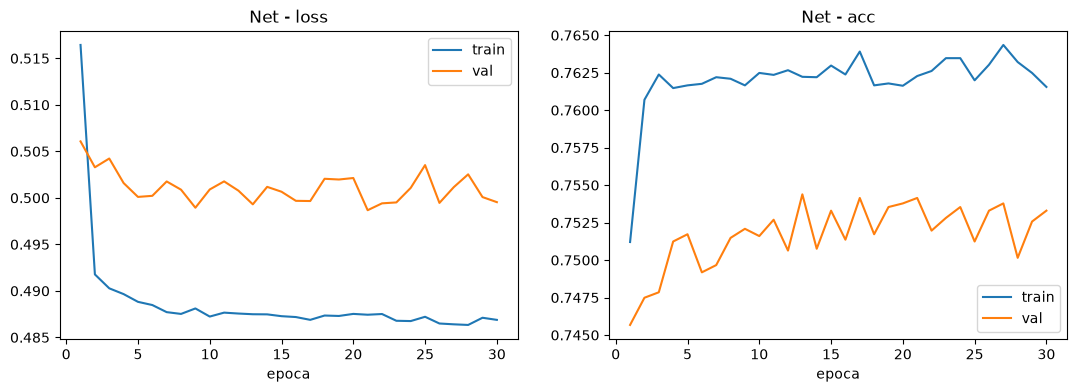

In [21]:
set_seed()
net = Net(n_features).to(device)
history_net = fit(net, train_loader, val_loader, epochs=30, lr=1e-2, print_every=5)
plot_history(history_net, 'Net')

Curbele pentru `train` și `val` sunt aproape suprapuse: modelul are doar câteva zeci de parametri și zeci de mii de exemple de antrenare, deci nu are capacitatea de a "memora" setul de antrenare. Spunem că modelul **nu face overfitting**. Problema opusă (*underfitting*) apare când modelul este prea simplu pentru date: atât eroarea de antrenare, cât și cea de validare rămân mari.

## 8. Regularizarea

**Overfitting**-ul apare când modelul învață pe de rost particularitățile setului de antrenare în loc de regulile generale: eroarea pe `train` continuă să scadă, dar eroarea pe `val` începe să crească. Metodele de **regularizare** limitează această tendință:

* **L2 (weight decay)**: se adaugă la funcția de cost termenul $\lambda \sum w^2$. Ponderile mari sunt penalizate, deci rețeaua preferă soluții cu ponderi mici, mai "netede". În PyTorch se activează prin parametrul `weight_decay` al optimizatorului.
* **L1**: se adaugă termenul $\lambda \sum |w|$. Spre deosebire de L2, împinge multe ponderi **exact spre 0**, deci produce rețele *rare* (sparse). Îl implementăm manual (vezi `weight_penalty_l1`).
* **Dropout**: la fiecare pas de antrenare, fiecare neuron este "oprit" (ieșirea pusă la 0) cu probabilitatea `p`. Rețeaua nu se poate baza pe un singur neuron și învață reprezentări redundante. La evaluare, dropout-ul este dezactivat (`model.eval()`).
* **Early stopping**: oprim antrenarea în epoca în care eroarea pe `val` este minimă. Numărul de epoci devine și el un hiper-parametru ales pe `val`.

Cum se comportă dropout-ul în modurile `train()` și `eval()`:

In [22]:
set_seed()
dropout_demo = FlexNet(n_features, hidden=(16,), dropout=0.5).to(device)
x_one = train_ds[0][0].unsqueeze(0).to(device) # un singur eșantion, cu dimensiunea de batch adăugată: [1, n_features]

with torch.no_grad():
  dropout_demo.train()
  print("train(): ", [round(dropout_demo(x_one).item(), 4) for _ in range(5)], "<- rezultat diferit la fiecare apel")
  dropout_demo.eval()
  print("eval():  ", [round(dropout_demo(x_one).item(), 4) for _ in range(5)], "<- rezultat determinist")

train():  [-0.0708, 0.03, 0.1103, 0.0978, -0.1725] <- rezultat diferit la fiecare apel
eval():   [0.042, 0.042, 0.042, 0.042, 0.042] <- rezultat determinist


### Provocăm overfitting

Ca să vedem efectul regularizării avem nevoie de un model care face overfitting. Îl obținem combinând un model **mare** (3 straturi ascunse de câte 256 de neuroni, adică peste 130.000 de parametri) cu **puține date de antrenare** (doar 500 de exemple din `train`). Setul de validare rămâne cel complet.

Clasa `Subset` creează un nou `Dataset` care conține doar eșantioanele cu indicii dați, fără să copieze datele.

In [23]:
N_SMALL = 500
generator = torch.Generator().manual_seed(RANDOM_SEED)
small_idx = torch.randperm(len(train_ds), generator=generator)[:N_SMALL].tolist()
small_train_ds = Subset(train_ds, small_idx)
small_train_loader = DataLoader(small_train_ds, batch_size=64, shuffle=True)
print("Exemple de antrenare:", len(small_train_ds), "| batch-uri pe epocă:", len(small_train_loader))

BIG = (256, 256, 256)
REG_EPOCHS = 200
REG_LR = 1e-3

reg_configs = {
  'fără regularizare': dict(),
  'L2 (weight decay)': dict(weight_decay=1e-2),
  'L1':                dict(l1_lambda=3e-4),
  'dropout 0.5':       dict(dropout=0.5),
}
# TODO: încercați diferite valori pentru weight_decay, l1_lambda și dropout. Ce se întâmplă dacă regularizarea este prea puternică?

reg_models, reg_histories = {}, {}
for name, cfg in reg_configs.items():
  print(f"--- {name} ---")
  set_seed() # aceeași inițializare a ponderilor pentru toate experimentele => comparație corectă
  model = FlexNet(n_features, hidden=BIG, dropout=cfg.get('dropout', 0.0)).to(device)
  reg_histories[name] = fit(model, small_train_loader, val_loader, epochs=REG_EPOCHS, lr=REG_LR,
                            weight_decay=cfg.get('weight_decay', 0.0), l1_lambda=cfg.get('l1_lambda', 0.0),
                            print_every=50)
  reg_models[name] = model

Exemple de antrenare: 500 | batch-uri pe epocă: 8
--- fără regularizare ---
epoca    1 | train loss 0.6109, acc 0.6980 | val loss 0.5370, acc 0.7404


epoca   50 | train loss 0.1981, acc 0.9160 | val loss 1.0622, acc 0.7182


epoca  100 | train loss 0.0755, acc 0.9740 | val loss 1.9919, acc 0.6973


epoca  150 | train loss 0.0279, acc 0.9920 | val loss 3.0262, acc 0.7077


epoca  200 | train loss 0.0065, acc 1.0000 | val loss 3.7186, acc 0.7061
--- L2 (weight decay) ---
epoca    1 | train loss 0.6296, acc 0.6800 | val loss 0.5648, acc 0.7418


...

epoca  200 | train loss 0.3225, acc 0.8580 | val loss 0.7269, acc 0.7326
--- dropout 0.5 ---
epoca    1 | train loss 0.6608, acc 0.6120 | val loss 0.5978, acc 0.7417


epoca   50 | train loss 0.4229, acc 0.8060 | val loss 0.5612, acc 0.7483


epoca  100 | train loss 0.3771, acc 0.8520 | val loss 0.6389, acc 0.7371


epoca  150 | train loss 0.3539, acc 0.8320 | val loss 0.6921, acc 0.7325


epoca  200 | train loss 0.3291, acc 0.8560 | val loss 0.8495, acc 0.7339


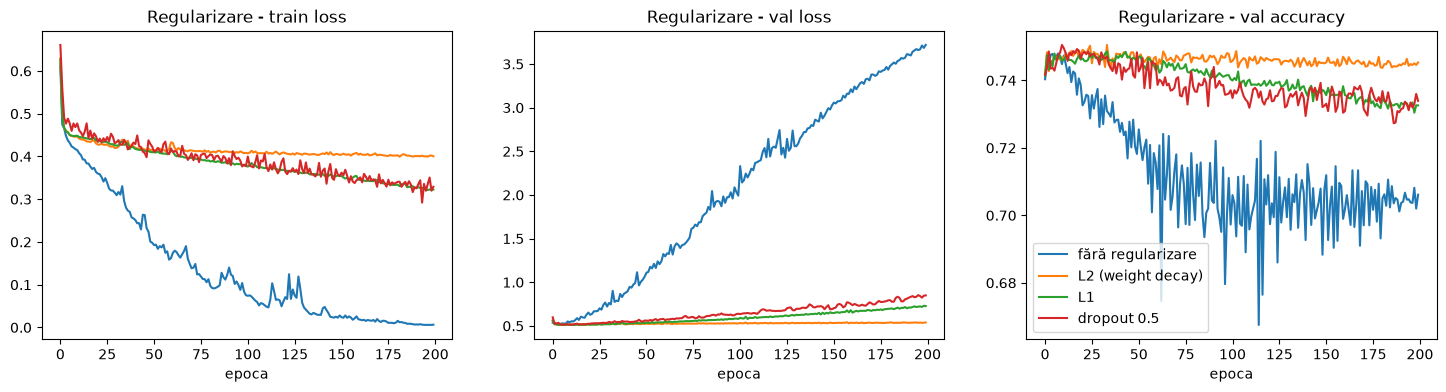

,train loss (final),val loss (final),val acc (final),cel mai mic val loss,epoca cu cel mai mic val loss
fără regularizare,0.0065,3.7186,0.7061,0.5138,4.0
L2 (weight decay),0.4003,0.5389,0.7453,0.5109,12.0
L1,0.3225,0.7269,0.7326,0.5107,12.0
dropout 0.5,0.3291,0.8495,0.7339,0.5128,6.0


In [24]:
plot_compare(reg_histories, 'Regularizare')
summarize(reg_histories)

Ce observăm:
* **Fără regularizare**, eroarea pe `train` scade aproape de 0 (modelul a memorat cele 500 de exemple), iar eroarea pe `val` scade la început, apoi crește continuu: overfitting clasic. Diferența dintre cele două curbe este *generalization gap*.
* Toate metodele de regularizare țin eroarea pe `val` mai jos și reduc diferența dintre `train` și `val`. Prețul plătit este o eroare mai mare pe `train` - modelul nu mai poate memora datele.
* Coloana *epoca cu cel mai mic val loss* arată ce ar face **early stopping**: pentru modelul fără regularizare, oprirea antrenării în acea epocă ar fi evitat cea mai mare parte a overfitting-ului.

Regularizarea se vede și direct în ponderi. Mai jos sunt histogramele tuturor ponderilor din rețea (scară logaritmică pe axa verticală) și evoluția normei ponderilor $\sqrt{\sum w^2}$ în timpul antrenării.

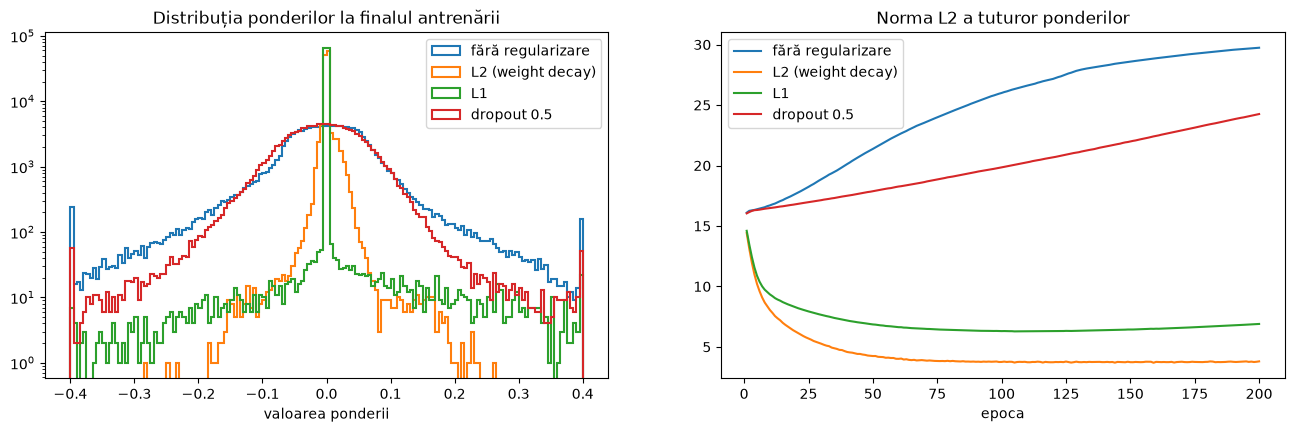

fără regularizare    |w| mediu = 0.0565   |w| maxim = 0.839   ponderi cu |w| < 1e-3:   1.3%
L2 (weight decay)    |w| mediu = 0.0032   |w| maxim = 0.283   ponderi cu |w| < 1e-3:  75.2%
L1                   |w| mediu = 0.0017   |w| maxim = 0.557   ponderi cu |w| < 1e-3:  98.6%
dropout 0.5          |w| mediu = 0.0497   |w| maxim = 0.577   ponderi cu |w| < 1e-3:   1.4%


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
bins = np.linspace(-0.4, 0.4, 161)
for name, model in reg_models.items():
  w_all = torch.cat([m.weight.detach().flatten().cpu() for m in linear_layers(model)]).numpy()
  axes[0].hist(np.clip(w_all, bins[0], bins[-1]), bins=bins, histtype='step', linewidth=1.5, label=name)
  axes[1].plot(range(1, REG_EPOCHS + 1), reg_histories[name]['weight_norm'], label=name)
axes[0].set_yscale('log')
axes[0].set_title('Distribuția ponderilor la finalul antrenării')
axes[0].set_xlabel('valoarea ponderii')
axes[0].legend()
axes[1].set_title('Norma L2 a tuturor ponderilor')
axes[1].set_xlabel('epoca')
axes[1].legend()
plt.show()

for name, model in reg_models.items():
  w_all = torch.cat([m.weight.detach().flatten().cpu() for m in linear_layers(model)])
  print(f"{name:20s} |w| mediu = {w_all.abs().mean():.4f}   |w| maxim = {w_all.abs().max():.3f}   ponderi cu |w| < 1e-3: {(w_all.abs() < 1e-3).float().mean() * 100:5.1f}%")

* Fără regularizare, norma ponderilor crește pe tot parcursul antrenării: ponderile mari îi permit rețelei să "memoreze" exemplele de antrenare.
* **L2** și **L1** împing amândouă spre 0 ponderile de care datele nu au nevoie. Cu 500 de exemple și peste 130.000 de ponderi, majoritatea ponderilor sunt în această situație, de aceea procentul de ponderi aproape nule este mare în ambele cazuri.
* Diferența dintre ele se vede la ponderile *importante*. Penalizarea L2 ($\lambda w^2$) crește rapid cu mărimea ponderii, deci L2 nu permite nicio pondere mare: **toate ponderile sunt mici** (vezi |w| maxim și distribuția îngustă). Penalizarea L1 ($\lambda |w|$) are aceeași "forță" pentru orice pondere, deci L1 duce la **multe ponderi nule și câteva ponderi mari**: rețeaua alege doar câteva conexiuni pe care le folosește din plin.
* **Dropout** nu acționează direct asupra ponderilor, deci distribuția lor rămâne asemănătoare cu cea fără regularizare; efectul lui se vede în curbele de validare.

Același lucru se vede în ponderile primului strat ascuns (256 de neuroni × 6 descriptori). Fiecare coloană este un neuron:

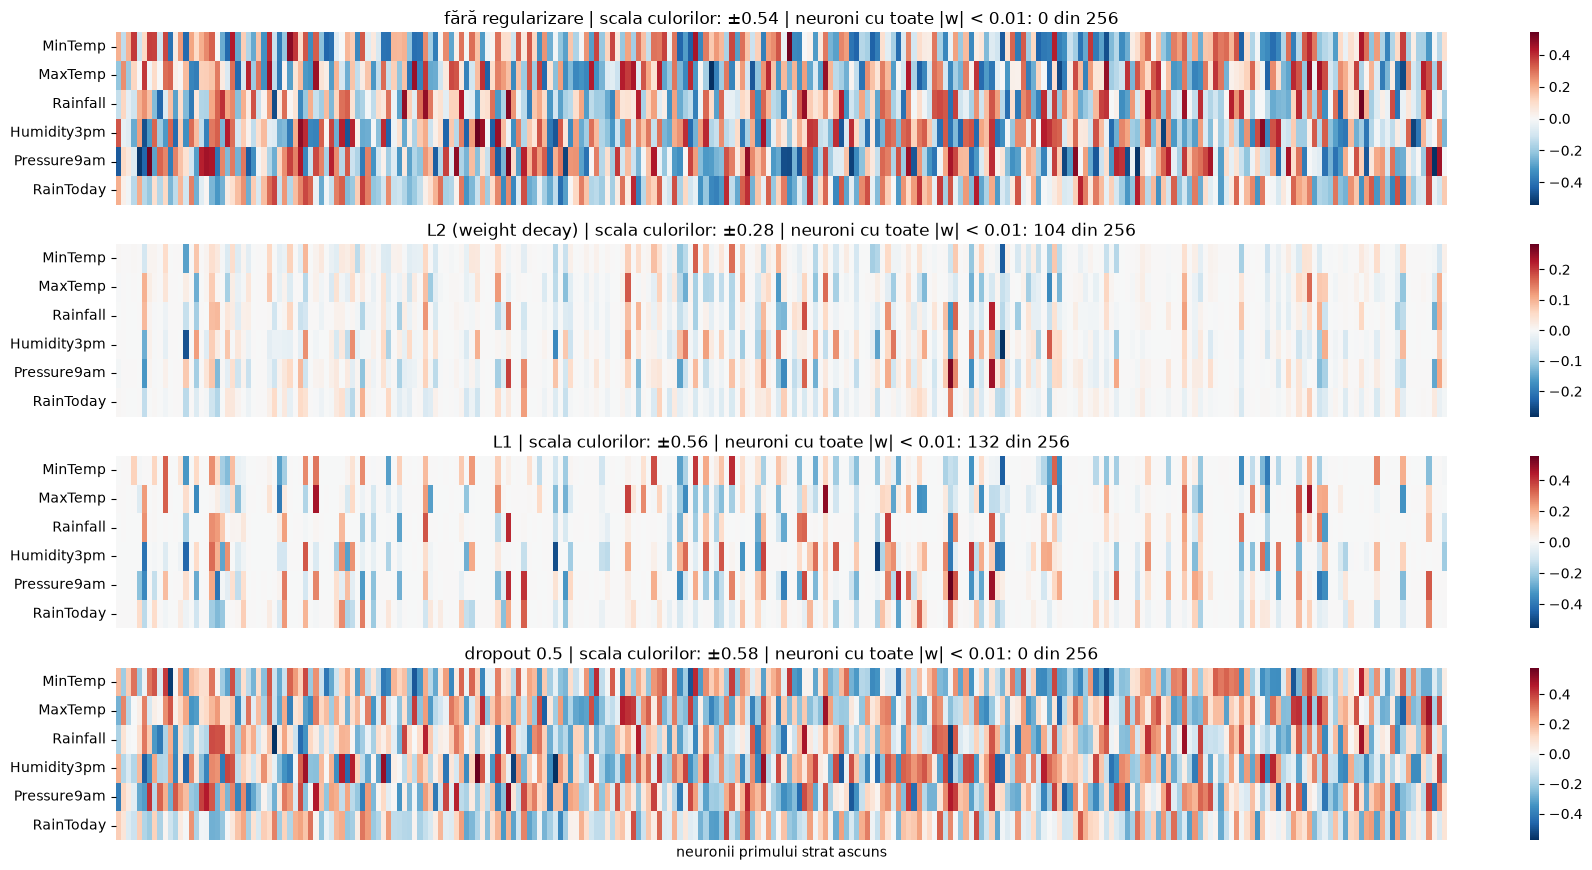

In [26]:
fig, axes = plt.subplots(len(reg_models), 1, figsize=(18, 2.2 * len(reg_models)), sharex=True)
for ax, (name, model) in zip(axes, reg_models.items()):
  W = linear_layers(model)[0].weight.detach().cpu().numpy() # [256 neuroni, 6 descriptori]
  lim = np.abs(W).max()
  n_off = int((np.abs(W).max(axis=1) < 1e-2).sum()) # neuroni cu toate ponderile de intrare aproape nule
  sns.heatmap(W.T, ax=ax, cmap='RdBu_r', center=0, vmin=-lim, vmax=lim, yticklabels=FEATURES, xticklabels=False)
  ax.set_title(f'{name} | scala culorilor: ±{lim:.2f} | neuroni cu toate |w| < 0.01: {n_off} din {W.shape[0]}')
axes[-1].set_xlabel('neuronii primului strat ascuns')
plt.tight_layout()
plt.show()

* Fără regularizare și cu dropout, toți neuronii folosesc toți descriptorii.
* Cu L2 și L1 apar multe coloane (aproape) albe: neuroni ale căror ponderi de intrare au fost aduse spre 0, deci practic au fost **eliminați** din rețea. Numărul lor este afișat în titlul fiecărui grafic.
* Comparați scala culorilor: neuronii rămași activi au, cu L1, ponderi de aproximativ două ori mai mari decât cu L2, exact diferența descrisă mai sus. Proprietatea L1 de a anula conexiuni este folosită în practică pentru a "tăia" (*pruning*) rețelele mari.

## 9. Alegerea hiper-parametrilor pe `val`

Revenim la setul de antrenare complet și comparăm câteva variante de model. Decizia o luăm **doar pe baza setului de validare**: alegem varianta cu cel mai mic val loss și numărul de epoci la care acesta a fost atins (early stopping).

--- Net 5-3 ---


epoca    1 | train loss 0.6181, acc 0.7076 | val loss 0.5738, acc 0.7371


epoca   10 | train loss 0.4908, acc 0.7615 | val loss 0.5047, acc 0.7468


epoca   20 | train loss 0.4896, acc 0.7618 | val loss 0.5037, acc 0.7472


epoca   30 | train loss 0.4888, acc 0.7623 | val loss 0.5031, acc 0.7486
--- MLP 64-32 ---


...

epoca   30 | train loss 0.4878, acc 0.7647 | val loss 0.4930, acc 0.7562
--- MLP 64-32 + L2 ---


epoca    1 | train loss 0.5252, acc 0.7543 | val loss 0.5031, acc 0.7483


epoca   10 | train loss 0.4829, acc 0.7654 | val loss 0.4936, acc 0.7558


epoca   20 | train loss 0.4813, acc 0.7668 | val loss 0.4915, acc 0.7554


epoca   30 | train loss 0.4802, acc 0.7666 | val loss 0.4913, acc 0.7555


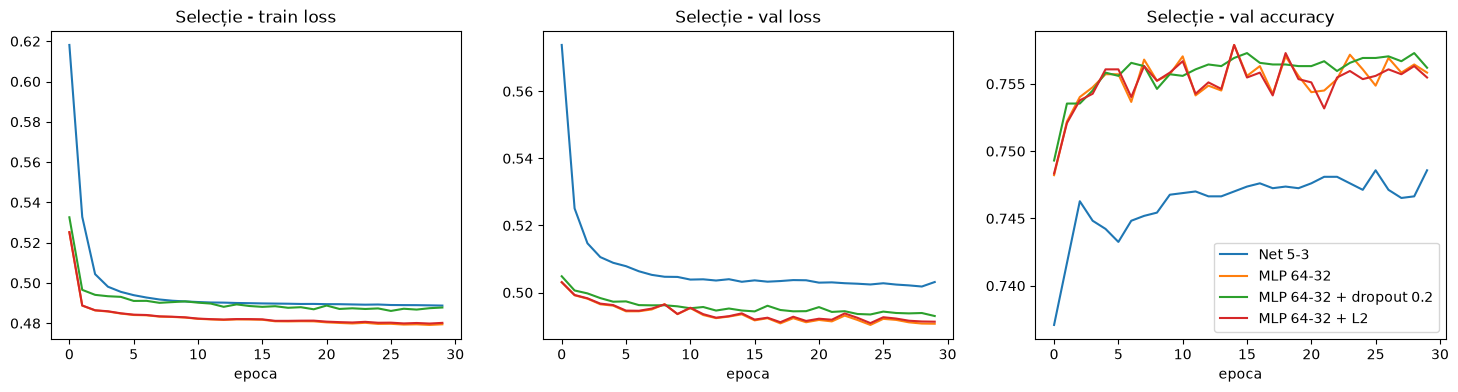

,train loss (final),val loss (final),val acc (final),cel mai mic val loss,epoca cu cel mai mic val loss
Net 5-3,0.4888,0.5031,0.7486,0.5018,29.0
MLP 64-32,0.4795,0.4907,0.7558,0.4903,25.0
MLP 64-32 + dropout 0.2,0.4878,0.4930,0.7562,0.4930,30.0
MLP 64-32 + L2,0.4802,0.4913,0.7555,0.4909,25.0


In [27]:
SEL_EPOCHS = 30
SEL_LR = 1e-3

candidates = {
  'Net 5-3':                  dict(hidden=(5, 3)),
  'MLP 64-32':                dict(hidden=(64, 32)),
  'MLP 64-32 + dropout 0.2':  dict(hidden=(64, 32), dropout=0.2),
  'MLP 64-32 + L2':           dict(hidden=(64, 32), weight_decay=1e-4),
}
# TODO: adăugați propriile variante (alte arhitecturi, alte rate de învățare, alte valori de regularizare)

sel_histories = {}
for name, cfg in candidates.items():
  print(f"--- {name} ---")
  set_seed()
  model = FlexNet(n_features, hidden=cfg['hidden'], dropout=cfg.get('dropout', 0.0)).to(device)
  sel_histories[name] = fit(model, train_loader, val_loader, epochs=SEL_EPOCHS, lr=SEL_LR,
                            weight_decay=cfg.get('weight_decay', 0.0), print_every=10)

plot_compare(sel_histories, 'Selecție')
results = summarize(sel_histories)
results

In [28]:
best_name = results['cel mai mic val loss'].idxmin()
best_cfg = candidates[best_name]
best_epochs = int(results.loc[best_name, 'epoca cu cel mai mic val loss'])
print(f"Varianta aleasă: {best_name} {best_cfg}, antrenată {best_epochs} epoci")

Varianta aleasă: MLP 64-32 {'hidden': (64, 32)}, antrenată 25 epoci


## 10. Antrenarea finală pe `train + val` și testarea

Toate deciziile au fost luate. Antrenăm un model **nou, de la zero**, cu hiper-parametrii aleși, pe reuniunea `train + val`. Pentru că setul de antrenare s-a schimbat, recalculăm și parametrii de normalizare pe noul set.

Nu mai avem un set de validare, deci nu mai putem face early stopping "pe viu": folosim numărul de epoci găsit anterior. Setul de antrenare are acum cu ~20% mai multe exemple, deci și mai mulți pași de optimizare pe epocă; în practică, păstrarea aceluiași număr de epoci funcționează bine.

In [29]:
x_final = pd.concat([x_train, x_val])
y_final = pd.concat([y_train, y_val])

final_scaler = StandardScaler().fit(x_final)
final_ds = WeatherDataset(final_scaler.transform(x_final), y_final)
test_ds = WeatherDataset(final_scaler.transform(x_test), y_test) # setul de test este folosit pentru prima dată abia acum
final_loader = DataLoader(final_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=1024, shuffle=False)

set_seed()
final_model = FlexNet(n_features, hidden=best_cfg['hidden'], dropout=best_cfg.get('dropout', 0.0)).to(device)
history_final = fit(final_model, final_loader, None, epochs=best_epochs, lr=SEL_LR,
                    weight_decay=best_cfg.get('weight_decay', 0.0), print_every=5)

epoca    1 | train loss 0.5207, acc 0.7548


epoca    5 | train loss 0.4858, acc 0.7627


epoca   10 | train loss 0.4838, acc 0.7637


epoca   15 | train loss 0.4826, acc 0.7635


epoca   20 | train loss 0.4822, acc 0.7652


epoca   25 | train loss 0.4815, acc 0.7656


Evaluarea pe `test` se face **o singură dată**. Dacă, după ce vedeți rezultatul, vă întoarceți să modificați modelul, setul de test devine un al doilea set de validare și nu mai oferă o estimare corectă.

In [30]:
classes = ['No rain', 'Raining']

test_loss, test_acc = evaluate(final_model, test_loader, nn.BCEWithLogitsLoss())
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}\n")

final_model.eval()
with torch.no_grad():
  y_pred = (final_model(test_ds.x.to(device)) > 0).int().cpu().numpy()
y_true = test_ds.y.int().numpy()

print(classification_report(y_true, y_pred, target_names=classes))

Test loss: 0.4789 | Test accuracy: 0.7682

              precision    recall  f1-score   support

     No rain       0.75      0.81      0.78      4132
     Raining       0.79      0.72      0.76      4133

    accuracy                           0.77      8265
   macro avg       0.77      0.77      0.77      8265
weighted avg       0.77      0.77      0.77      8265



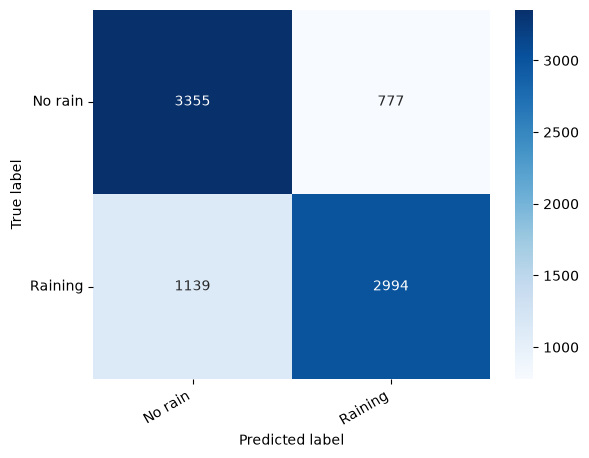

In [31]:
cm = confusion_matrix(y_true, y_pred)
df_cm = pd.DataFrame(cm, index=classes, columns=classes)

hmap = sns.heatmap(df_cm, annot=True, fmt="d", cmap='Blues')
hmap.yaxis.set_ticklabels(hmap.yaxis.get_ticklabels(), rotation=0, ha='right')
hmap.xaxis.set_ticklabels(hmap.xaxis.get_ticklabels(), rotation=30, ha='right')
plt.ylabel('True label')
plt.xlabel('Predicted label');

## 11. Ce au învățat ponderile?

### 11.1 Ponderile primului strat

Fiecare neuron din primul strat ascuns calculează o combinație liniară a descriptorilor de intrare. Pentru că datele sunt standardizate, toți descriptorii au aceeași scală, deci mărimea ponderilor este comparabilă între descriptori: o pondere mare (în valoare absolută) înseamnă că neuronul este sensibil la acel descriptor.

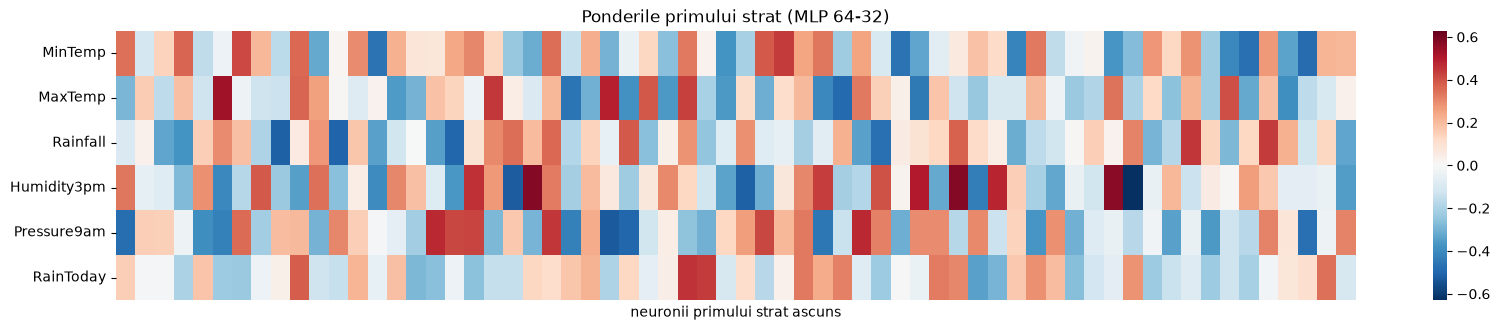

In [32]:
W1 = linear_layers(final_model)[0].weight.detach().cpu().numpy() # [neuroni, descriptori]
lim = np.abs(W1).max()

plt.figure(figsize=(min(1 + 0.3 * W1.shape[0], 20), 3.5))
sns.heatmap(W1.T, cmap='RdBu_r', center=0, vmin=-lim, vmax=lim, yticklabels=FEATURES, xticklabels=False)
plt.xlabel('neuronii primului strat ascuns')
plt.title(f'Ponderile primului strat ({best_name})')
plt.show()

Comparăm importanța medie a fiecărui descriptor pentru rețea (media lui $|w|$ pe toți neuronii primului strat) cu corelația simplă dintre descriptor și etichetă, calculată pe `train`.

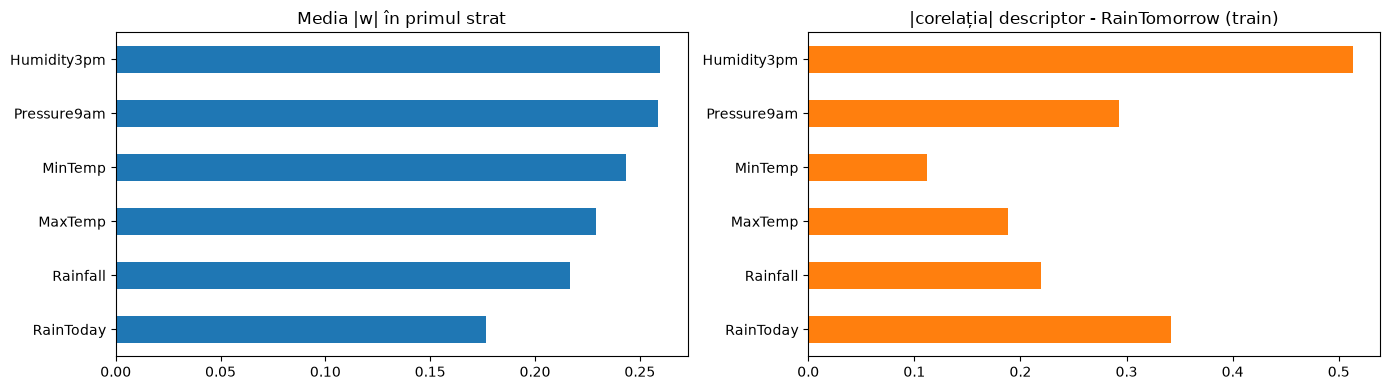

In [33]:
importance = pd.Series(np.abs(W1).mean(axis=0), index=FEATURES)
correlation = x_train.corrwith(y_train).abs()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
importance.sort_values().plot.barh(ax=axes[0], color='tab:blue')
axes[0].set_title('Media |w| în primul strat')
correlation[importance.sort_values().index].plot.barh(ax=axes[1], color='tab:orange')
axes[1].set_title('|corelația| descriptor - RainTomorrow (train)')
plt.tight_layout()
plt.show()

Descriptorul cel mai puternic corelat cu eticheta, `Humidity3pm`, primește și cele mai mari ponderi: rețeaua a "descoperit" singură care măsurătoare este cea mai relevantă pentru predicția ploii. În rest, ordinea nu coincide cu cea a corelațiilor, din două motive:
* corelația măsoară doar relația liniară dintre **un singur** descriptor și etichetă, în timp ce rețeaua combină descriptorii neliniar. De exemplu, `MinTemp` și `MaxTemp` sunt slab corelate cu ploaia luate separat, dar diferența dintre ele (amplitudinea termică) este informativă;
* descriptorii redundanți își "împart" importanța. `RainToday` este practic `Rainfall > 1mm`, deci rețeaua poate folosi oricare dintre ei, iar `RainToday` ajunge să primească ponderi mici, deși singur este puternic corelat cu eticheta.

Media |w| a primului strat este doar un indicator aproximativ al importanței: ponderile straturilor următoare pot amplifica sau anula contribuția unui neuron.

### 11.2 Neuroni morți

Un neuron urmat de ReLU este "mort" dacă ieșirea lui este 0 pentru toate intrările: nu mai contribuie la rezultat și nici nu mai primește gradient, deci nu mai poate învăța. Neuronii mor de obicei când o actualizare prea mare (rată de învățare mare) îi împinge într-o zonă în care sunt negativi pentru toate datele. La extrema cealaltă, un neuron activ pe 100% din exemple se comportă liniar, deci nu adaugă nimic în plus față de un strat liniar.

Măsurăm, pentru fiecare neuron din primul strat, pe ce procent din exemple este activ (ieșire > 0).

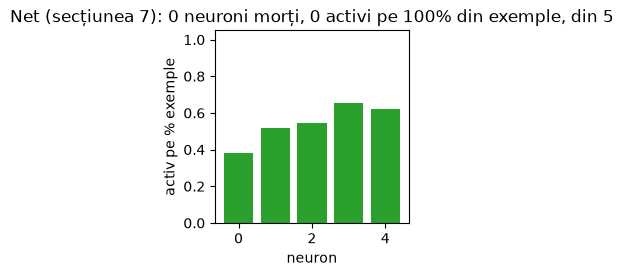

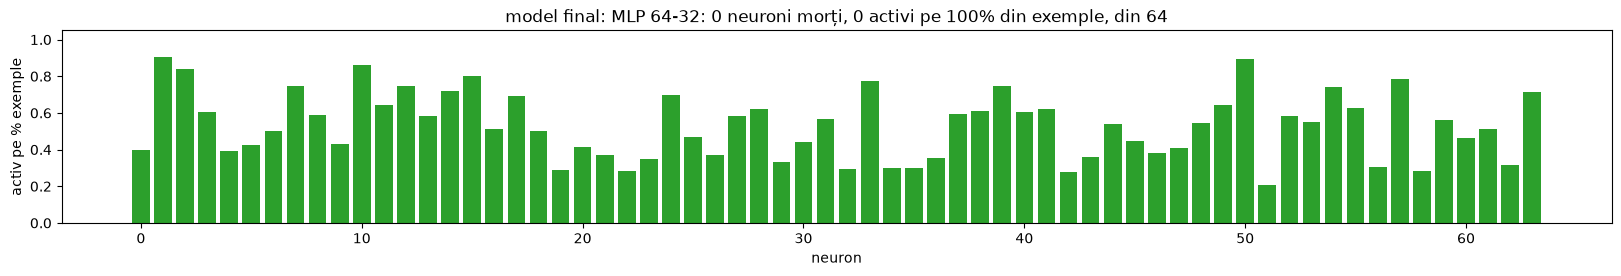

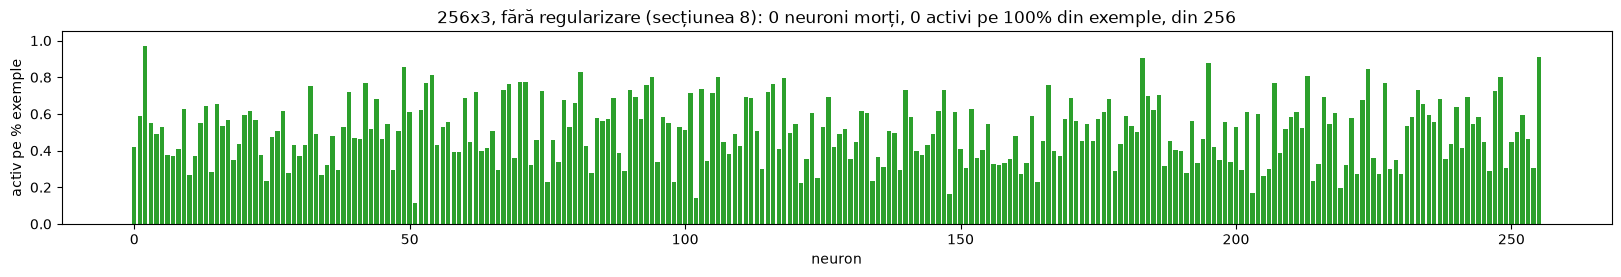

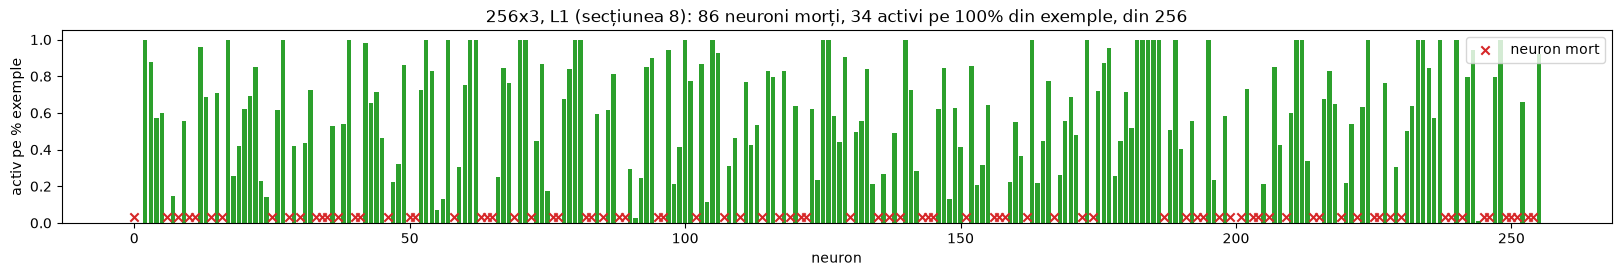

In [34]:
@torch.no_grad()
def first_layer_activity(model, x):
  model.eval()
  z = linear_layers(model)[0](x.to(device)) # ieșirea primului strat, înainte de ReLU
  return (z > 0).float().mean(dim=0).cpu().numpy() # procentul de exemple pentru care ReLU este activ

for title, model, data in [('Net (secțiunea 7)', net, val_ds.x), (f'model final: {best_name}', final_model, test_ds.x),
                           ('256x3, fără regularizare (secțiunea 8)', reg_models['fără regularizare'], val_ds.x),
                           ('256x3, L1 (secțiunea 8)', reg_models['L1'], val_ds.x)]:
  activity = first_layer_activity(model, data)
  plt.figure(figsize=(min(1 + 0.3 * len(activity), 20), 2.5))
  plt.bar(range(len(activity)), activity, color='tab:green')
  dead = np.where(activity == 0)[0]
  plt.scatter(dead, np.full(len(dead), 0.03), color='tab:red', marker='x', label='neuron mort') # barele de înălțime 0 nu s-ar vedea
  plt.ylim(0, 1.05)
  if len(dead):
    plt.legend(loc='upper right')
  plt.ylabel('activ pe % exemple')
  plt.xlabel('neuron')
  plt.title(f'{title}: {len(dead)} neuroni morți, {int((activity == 1).sum())} activi pe 100% din exemple, din {len(activity)}')
  plt.show()

* Modelele fără L1 folosesc toți neuronii: fiecare neuron este activ pentru o parte din exemple și inactiv pentru restul, deci contribuie neliniar la decizie.
* Modelul cu L1 are o mulțime de neuroni morți (marcați cu ×). Majoritatea sunt neuronii "eliminați" din graficul cu ponderi din secțiunea 8: cu ponderile de intrare aproape nule, ieșirea lor este determinată de bias. Dacă bias-ul este negativ, neuronul este mort; dacă este pozitiv, neuronul este activ pe 100% din exemple și ieșirea lui este practic o constantă. În ambele cazuri, neuronul nu mai contribuie la decizie.

### 11.3 Evoluția ponderilor în timpul antrenării

Urmărim fiecare pondere a primului strat al modelului `Net` (secțiunea 7) de la inițializare până la final. Fiecare linie este o pondere; culoarea indică descriptorul de intrare corespunzător.

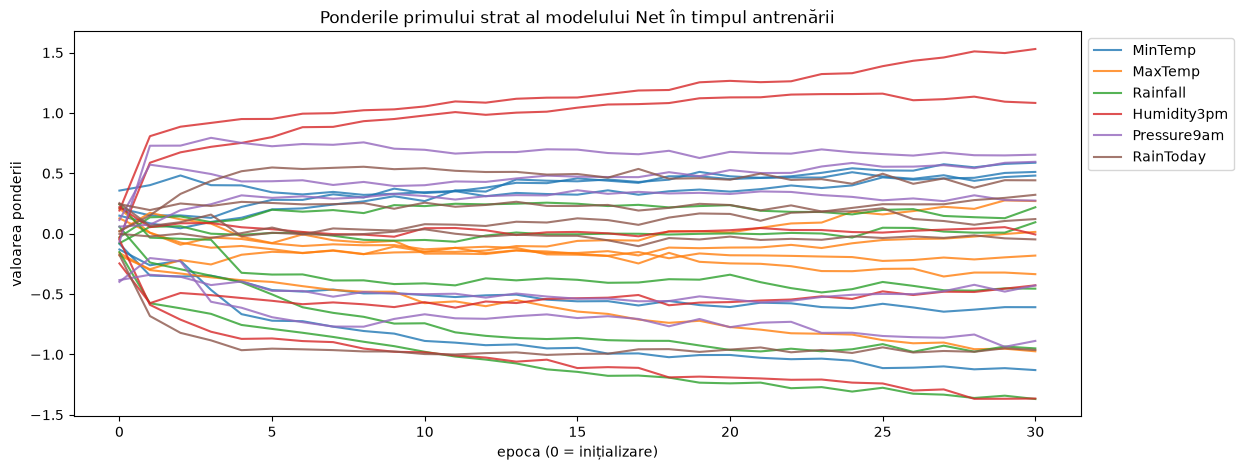

In [35]:
traj = torch.stack(history_net['fc1']).numpy() # [epoci + 1, neuroni, descriptori]
colors = plt.cm.tab10(np.arange(n_features))

fig, ax = plt.subplots(figsize=(13, 5))
for j in range(traj.shape[2]):     # descriptor
  for i in range(traj.shape[1]):   # neuron
    ax.plot(traj[:, i, j], color=colors[j], alpha=0.8, label=FEATURES[j] if i == 0 else None)
ax.set_xlabel('epoca (0 = inițializare)')
ax.set_ylabel('valoarea ponderii')
ax.set_title('Ponderile primului strat al modelului Net în timpul antrenării')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

Ce se observă:
* cele mai mari schimbări au loc în **prima epocă**, când rețeaua pleacă de la ponderi aleatoare și gradienții sunt mari; după aceea ponderile se modifică tot mai lent, pe măsură ce funcția de cost se apropie de un minim;
* ponderile cu cea mai mare valoare absolută la final aparțin, de regulă, lui `Humidity3pm`, în acord cu secțiunea 11.1;
* unele ponderi continuă să crească lent chiar și după ce funcția de cost nu mai scade: fără regularizare, nimic nu oprește creșterea lor.

TODO: rulați din nou secțiunea 7 cu `lr=0.1` sau `lr=1.0` și refaceți graficele din 11.2 și 11.3. Apar neuroni morți? Cum arată traiectoriile ponderilor lor?

## 12. TODO

1. Adăugați cel puțin 2 descriptori noi în lista `keep` (secțiunea 2). Cum se modifică acuratețea pe `val`? Ce ponderi primesc noii descriptori în secțiunea 11?
2. Propuneți o altă strategie pentru valorile lipsă (NaN) în locul eliminării intrărilor (de exemplu completarea cu media calculată pe `train`).
3. Rulați experimentele cu diferite grade de dezechilibru între clase (no_rain = 3.5x, 3x, 2x rain) și implementați o metodă de over-sampling. Urmăriți precision/recall pentru fiecare clasă, nu doar acuratețea.
4. Modificați arhitectura (număr de straturi, neuroni, funcții de activare), optimizatorul și rata de învățare. Respectați protocolul: decizia se ia doar pe `val`. Realizați un număr minim de 5 optimizări, după care testați pe `test`.
5. În secțiunea 8, variați intensitatea regularizării (`weight_decay`, `l1_lambda`, `dropout`). Ce se întâmplă când este prea mare? Dar dacă folosiți `N_SMALL = 5000`?
6. Rulați antrenarea atât pe CPU, cât și pe GPU (în Colab: *Runtime → Change runtime type*). Pentru un model atât de mic, GPU-ul este mai rapid? Ce se întâmplă dacă măriți `BATCH_SIZE` sau dimensiunea modelului?